In [220]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import os
import glob
from scipy.signal import savgol_filter
import pandas as pd
import seaborn as sns
import math
from scipy.stats import exponnorm
import scipy.special as sse
from scipy.optimize import curve_fit
from scipy import stats
#from pomegranate import *
from sklearn.metrics import mean_squared_error
from sklearn.mixture import GaussianMixture
from scipy.stats import norm
from scipy.special import rel_entr
from sklearn.neighbors import KernelDensity
import scipy.optimize as opt
import scipy.stats as st

In [9]:
file_location = os.path.join('C:\\Users\\Austin\\Desktop\\cell_model\\fig_data', '*imt*')
filenames = glob.glob(file_location)
c1 = "tab:blue"
c2 = "tab:red"

In [3]:
IMTs = []
for f in filenames:
    tmp_df = pd.read_csv(f)
    tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    IMTs.append(tmp_df)

ii=0
for df in IMTs:
    df["IMT"] = df["Division"] - df["Mitotic Frame"]
    df["G1"] = df["Green On"] - df["Mitotic Frame"]
    df["S-M"] = df["Division"] - df["Green On"]
    if ii == 2 or ii == 3 or ii == 6 or ii == 7:
        df["IMT_t"] = df["IMT"] * (32/60)
        df["G1_t"] = df["G1"] * (32/60)
        df["S-M_t"] = df["S-M"] * (32/60)
    else:
        df["IMT_t"] = df["IMT"] * (20/60)
        df["G1_t"] = df["G1"] * (20/60)
        df["S-M_t"] = df["S-M"] * (20/60)
    #df = df[(df["IMT_t"] ==27)].reset_index(drop=True)
    ii+=1
    
stiffs = [0.2, 0.2, 0.6, 0.6, 4, 4, 55, 55]
ii=0
for df in IMTs:
    tmp_stiff = np.ones(len(df))*stiffs[ii]
    df.insert(0, "Stiffness", tmp_stiff)
    if ii % 2 == 0:
        df["Drug"] = "DMSO"
    else:
        df["Drug"] = "ERL"    
    ii+=1

all_IMTs = pd.concat(IMTs, ignore_index=True, sort=False)
centers = np.arange(0.5, 100.5, 1)

In [246]:
def emg_fit_func(x, l, s, m):
    return 0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s)) # exponential gaussian

In [12]:
def emg_fit_func_2(x, l, s, m, l_2, s_2, m_2, w):
    return w*(0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s))) + (1-w)*(0.5*l_2*np.exp(0.5*l_2*(2*m_2+l_2*s_2*s_2-2*x))*sse.erfc((m_2+l_2*s_2*s_2-x)/(np.sqrt(2)*s_2))) # exponential gaussian

In [567]:
def logl_emg(log_par, data):
    l,s,m = np.exp(log_par)
    return np.log(list(emg_fit_func(data, l, s, m))).sum()

In [587]:
def logl_emgv2(log_par, data):
    l,s,m = np.exp(log_par)
    eps = 10e-12
    return np.log(list(emg_fit_func(data, l, s, m)+eps)).sum()

In [317]:
def logl_emg2(log_par, data):
    l,s,m,l_2,s_2,m_2,w = np.exp(log_par)
    return np.log(list(emg_fit_func_2(data, l , s, m, l_2, s_2, m_2, w))).sum()

In [660]:
def logl_emg2v2(log_par, data):
    l,s,m,l_2,s_2,m_2,w = np.exp(log_par)
    eps = 10e-12
    return np.log(list(emg_fit_func_2(data, l , s, m, l_2, s_2, m_2, w)+eps)).sum()

In [96]:
def calculate_aic(LL, num_params):
    aic = 2*num_params - 2*LL
    return aic

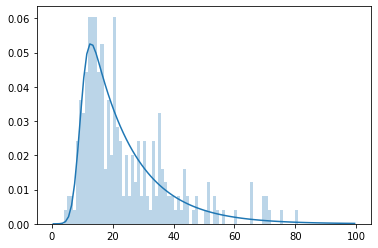

In [497]:
h, edges =np.histogram(IMTs[5]["G1_t"], bins=range(0,101), density=True)
out = plt.stairs(h, edges, fill=True, color=c1, alpha=0.3)
popt,pcov=(curve_fit(emg_fit_func, centers, h))
fitted_curve=list(emg_fit_func(centers,*popt))
plt.plot(centers, fitted_curve, color=c1)

In [498]:
popt

array([0.07169705, 2.11556209, 9.46476751])

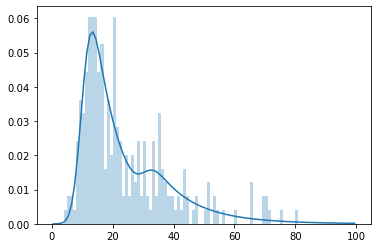

In [320]:
emg_init = [0.07, 2, 9.5, 0.07, 2, 35, 0.5]
emg_bounds = [[0, 0, 0, 0, 0, 0, 0], [2, 20, 30, 2, 100, 100, 1]]
h, edges =np.histogram(IMTs[5]["G1_t"], bins=range(0,101), density=True)
out = plt.stairs(h, edges, fill=True, color=c1, alpha=0.3)
popt2,pcov2=(curve_fit(emg_fit_func_2, centers, h, p0=emg_init, bounds=emg_bounds, maxfev=5000))
fitted_curve=list(emg_fit_func_2(centers,*popt2))
plt.plot(centers, fitted_curve, color=c1)

log_par2 = [math.log(x) for x in popt2 ]


In [321]:
log_par2

[-2.1456424897556428,
 0.8944307289493798,
 2.314872310483499,
 -2.709072129931361,
 1.0797014394698734,
 3.412032975841371,
 -0.2342946087765762]

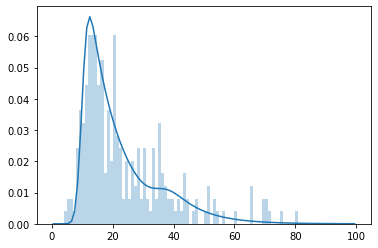

In [67]:
emg_init = [0.07, 2, 9.5, 0.07, 2, 20, 0.5]
emg_bounds = [[0, 0, 0, 0, 0, 0, 0], [1, 20, 30, 1, 20, 50, 1]]
h, edges =np.histogram(IMTs[5]["G1_t"], bins=range(0,101), density=True)
out = plt.stairs(h, edges, fill=True, color=c1, alpha=0.3)
popt,pcov=(curve_fit(emg_fit_func_2, centers, h, p0=emg_init, bounds=emg_bounds))
fitted_curve=list(emg_fit_func_2(centers,0.1,1.5,10,0.1,3.6,35,0.9))
plt.plot(centers, fitted_curve, color=c1)

In [359]:
data = np.array(IMTs[0]["G1_t"])
data = data[~np.isnan(data)]
LL_emg2 = np.log(list(emg_fit_func_2(data,*popt2))).sum()
emg2_aic = calculate_aic(LL_emg2, 7)

In [135]:
LL_emg2
    

-1029.0240551252755

In [499]:
data = np.array(IMTs[5]["G1_t"])
data = data[~np.isnan(data)]

params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
params_r = [exp_c, params[2], params[1]]
emg_aic = calculate_aic(LL_emg, 3)
y1 = exponnorm.pdf(centers, K=params[0], loc=params[1], scale=params[2] )
y2 = emg_fit_func(centers,*params_r)
y3 = exponnorm.pdf(centers, *params)

#test = exponnorm.logpdf(data,*params)

LL_emg = np.log(list(emg_fit_func(data,*popt))).sum()
LLH = np.log(list(emg_fit_func(data,*params_r))).sum()
log_par = [math.log(x) for x in params_r ]
test = logl_emg(log_par, data)



In [501]:
params_r

[0.07123931134528388, 5.199658557038131, 9.737917148685359]

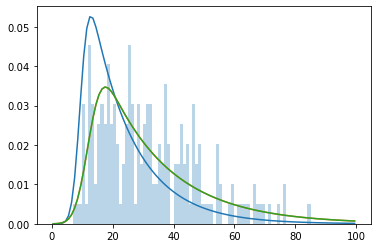

In [373]:
plt.plot(centers,y)
plt.plot(centers,y1)
plt.plot(centers,y2)
#plt.plot(centers,y3)
h, edges =np.histogram(IMTs[1]["G1_t"], bins=range(0,101), density=True)
out = plt.stairs(h, edges, fill=True, color=c1, alpha=0.3)

In [492]:
def emg_mle(data, log_par):
    res = opt.minimize(
    fun=lambda log_params, data: -logl_emg(log_params, data),
    x0=np.array(log_par), args=(data,), method='BFGS')
    log_p = res.x
    params = [np.exp(y) for y in log_p]
    
    return log_p, params

In [533]:
def emg_mle_v2(data, log_par):
    res = opt.minimize(
    fun=lambda log_params, data: -logl_emgv2(log_params, data),
    x0=np.array(log_par), args=(data,), method='BFGS')
    log_p = res.x
    params = [np.exp(y) for y in log_p]
    
    return log_p, params

In [476]:
def emg2_mle(data, log_par2):
    res = opt.minimize(
    fun=lambda log_params, data: -logl_emg2(log_params, data),
    x0=np.array(log_par2), args=(data,), method='BFGS')
    log_p = res.x
    params = [np.exp(y) for y in log_p]
    
    return log_p, params

In [616]:
def emg2_mle_v2(data, log_par2):
    res = opt.minimize(
    fun=lambda log_params, data: -logl_emg2v2(log_params, data),
    x0=np.array(log_par2), args=(data,), method='BFGS')
    log_p = res.x
    params = [np.exp(y) for y in log_p]
    
    return log_p, params

In [661]:
data = np.array(IMTs[5]["G1_t"])
data = data[~np.isnan(data)]

In [556]:
data[0]

20.333333333333332

In [645]:
#[log_p, params] = emg_mle(data, log_par)
[log_p2, params2] = emg_mle_v2(data, log_par)

In [624]:
params

[0.04854843975923593, 3.4920372901630023, 12.217016259604788]

In [646]:
params2

[0.1966313221636127, 1.0563662673341019, 10.133925932108705]

In [647]:
LL = logl_emg(log_p, data)
LL2 = logl_emg(log_p2, data)

In [648]:
LL2

-496.5290602591126

In [528]:
test = np.log(list(emg_fit_func(data, l, s, m))).sum()

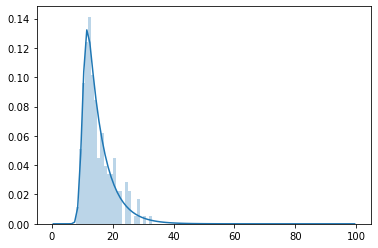

In [649]:
# y3 = emg_fit_func(centers,*params)
# plt.plot(centers,y3)
y2 = emg_fit_func(centers,*params2)
plt.plot(centers,y2)
h, edges =np.histogram(IMTs[7]["G1_t"], bins=range(0,101), density=True)
out = plt.stairs(h, edges, fill=True, color=c1, alpha=0.3)

test = logl_emg(log_p2, data)
test1 = calculate_aic(test, 3)

In [650]:
test1

999.0581205182252

In [662]:
[log_p2, params2] = emg2_mle_v2(data, log_par2)

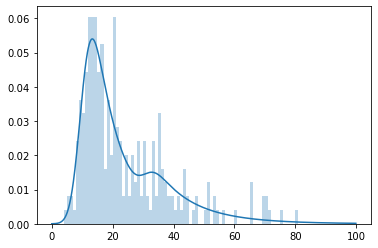

In [665]:
x1 = np.arange(0,100,0.1)
y4 = emg_fit_func_2(x1,*params2)
plt.plot(x1,y4)
h, edges =np.histogram(IMTs[5]["G1_t"], bins=range(0,101), density=True)
out = plt.stairs(h, edges, fill=True, color=c1, alpha=0.3)

test = logl_emg2(log_p2, data)
test1 = calculate_aic(test, 7)

In [643]:
test1

1669.438500792693

In [384]:
params2

[0.05975060232014785,
 1.9591444466962173,
 10.240950980209083,
 0.07378956952423764,
 8.172813734962286,
 28.12723552782528,
 0.6029264499812855]

In [659]:
log_par2

[-2.1456424897556428,
 0.8944307289493798,
 2.314872310483499,
 -2.709072129931361,
 1.0797014394698734,
 3.412032975841371,
 -0.2342946087765762]